# Import LW-DETR ONNX in Aidge and Compare With ONNX Runtime

This notebook loads `output/onnx_export/tiny/inference_model.sim.onnx`, runs the same images through ONNX Runtime and Aidge, then compares the raw model outputs. It intentionally removes the quantization flow from the Aidge PTQ tutorial.

Expected model outputs are `dets` and `labels`, matching the LW-DETR export path.

## Configuration

In [1]:
from pathlib import Path

cwd = Path.cwd().resolve()
if cwd.name == "deploy":
    DEPLOY_DIR = cwd
    REPO_ROOT = cwd.parent
    DEMO_DIR = REPO_ROOT / "demo"
else:
    REPO_ROOT = cwd
    DEPLOY_DIR = REPO_ROOT / "deploy"
    DEMO_DIR = REPO_ROOT / "demo"

IMAGE_DIR = DEMO_DIR / "images"
IMG_SIZE = 640
AIDGE_BACKEND = "cpu"
LOG_AIDGE_OUTPUTS = False
AIDGE_OBSERVER_DIR = "aidge_lwdetr_observer"

MODEL_PATH = REPO_ROOT / "output/onnx_export/tiny/inference_model.sim.onnx"  # float model
MODEL_PATH = REPO_ROOT / "output/export_tiny_ptq/inference_model.sim.onnx" # Fake quant model (float layernorm)


assert MODEL_PATH.exists(), f"ONNX model not found: {MODEL_PATH.resolve()}"
print("model:", MODEL_PATH.resolve())
print("image_dir:", IMAGE_DIR.resolve())

model: /home/tl286648/dev/model/LW-DETR/output/export_tiny_ptq/inference_model.sim.onnx
image_dir: /home/tl286648/dev/model/LW-DETR/demo/images


## Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import onnxruntime as ort
import onnx
from onnx import helper, shape_inference, TensorProto

import aidge_core
import aidge_onnx
import aidge_backend_cpu

# try:
#     import aidge_model_explorer
# except Exception:
#     aidge_model_explorer = None

aidge_core.Log.set_console_level(aidge_core.Level.Error)
print("Available Aidge backends:", aidge_core.Tensor.get_available_backends())

Running cmake --build & --install in /home/tl286648/dev/aidge_project/aidge/aidge/aidge_backend_cpu/build
Available Aidge backends: {'cpu', 'export_serialize'}


In [3]:
import aidge_model_explorer
from aidge_gui import visualize

## Load Images

Put test images under `deploy/images/`. The notebook uses the first few common image files it finds there.

In [4]:
image_paths = []
for pattern in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"):
    image_paths.extend(sorted(IMAGE_DIR.glob(pattern)))

if not image_paths:
    raise FileNotFoundError(
        f"No images found in {IMAGE_DIR.resolve()}. "
        "Create deploy/images and copy a few .jpg/.png files there."
    )

# image_paths = image_paths[:5]
print("images:")
for path in image_paths:
    print(" -", path)

images:
 - /home/tl286648/dev/model/LW-DETR/demo/images/000000062808.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/000000212226.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/000000231527.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/000000496954.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/000000578922.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/animal.jpg
 - /home/tl286648/dev/model/LW-DETR/demo/images/objects.jpg


## Preprocess Like `deploy/benchmark.py`

LW-DETR export/evaluation uses square resize to 640, `ToTensor`, then ImageNet normalization.

input: (1, 3, 640, 640) float32
original_size: (800, 600)


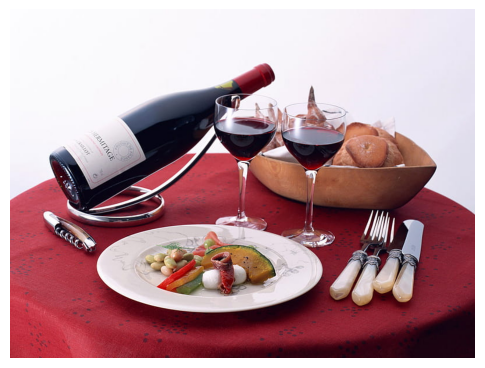

In [5]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)


def load_image(path):
    return Image.open(path).convert("RGB")


def preprocess(image, img_size=IMG_SIZE):
    original_size = image.size  # PIL gives (width, height)
    resized = image.resize((img_size, img_size), Image.BILINEAR)
    array = np.asarray(resized).astype(np.float32) / 255.0
    chw = np.transpose(array, (2, 0, 1))
    normalized = (chw - MEAN) / STD
    batch = normalized[None].astype(np.float32)
    return batch, original_size


image = load_image(image_paths[6])
input_tensor, original_size = preprocess(image)
print("input:", input_tensor.shape, input_tensor.dtype)
print("original_size:", original_size)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## ONNX Runtime Reference Flow

This is the normal ONNX load/run path used as the reference for comparison.

In [6]:
ort_session = ort.InferenceSession(str(MODEL_PATH), providers=["CPUExecutionProvider"])
ort_input_name = ort_session.get_inputs()[0].name
ort_output_names = [output.name for output in ort_session.get_outputs()]

print("ONNX Runtime input:", ort_input_name)
print("ONNX Runtime outputs:", ort_output_names)


def run_onnxruntime(batch):
    outputs = ort_session.run(None, {ort_input_name: batch})
    return dict(zip(ort_output_names, outputs))


ort_outputs = run_onnxruntime(input_tensor)
for name, value in ort_outputs.items():
    print(name, value.shape, value.dtype, "min", value.min(), "max", value.max())

ONNX Runtime input: input
ONNX Runtime outputs: ['dets', 'labels']
dets (1, 100, 4) float32 min 0.028051458 max 1.0971718
labels (1, 100, 91) float32 min -9.696743 max 1.9450946


## Plot ONNX Runtime Detections

This runs immediately after the ONNX Runtime forward pass. Labels are COCO category IDs; names are shown for the standard COCO IDs.

kept 5 detections
wine glass      score=0.8749 box=[343.3 135.3 458.6 395.3]
wine glass      score=0.7582 box=[465.  144.4 579.9 416.2]
bottle          score=0.6449 box=[ 67.8  92.8 452.5 382.5]
carrot          score=0.5416 box=[250.3 428.8 322.6 484.9]
knife           score=0.5093 box=[656.7 357.9 708.4 507.2]


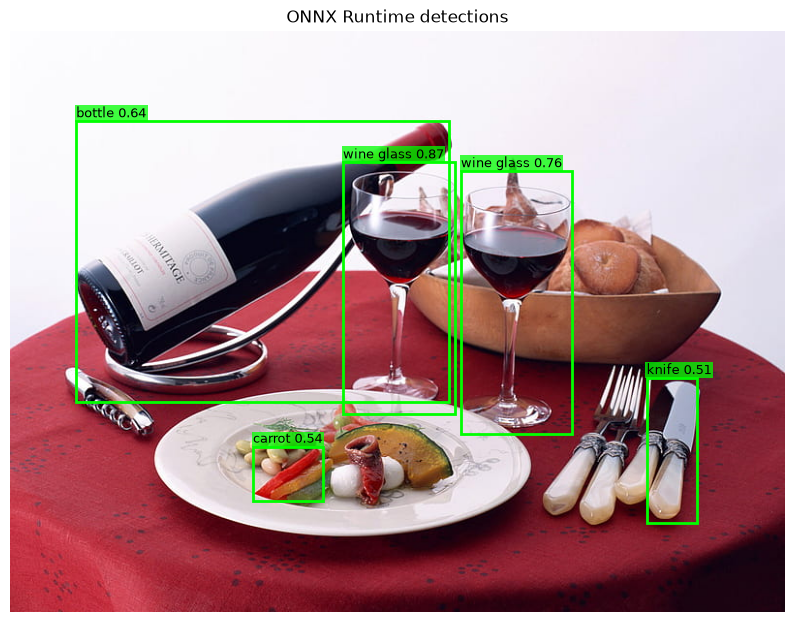

In [7]:
from matplotlib import patches

COCO_NAMES = {
    1: "person", 2: "bicycle", 3: "car", 4: "motorcycle", 5: "airplane",
    6: "bus", 7: "train", 8: "truck", 9: "boat", 10: "traffic light",
    11: "fire hydrant", 13: "stop sign", 14: "parking meter", 15: "bench",
    16: "bird", 17: "cat", 18: "dog", 19: "horse", 20: "sheep", 21: "cow",
    22: "elephant", 23: "bear", 24: "zebra", 25: "giraffe", 27: "backpack",
    28: "umbrella", 31: "handbag", 32: "tie", 33: "suitcase", 34: "frisbee",
    35: "skis", 36: "snowboard", 37: "sports ball", 38: "kite", 39: "baseball bat",
    40: "baseball glove", 41: "skateboard", 42: "surfboard", 43: "tennis racket",
    44: "bottle", 46: "wine glass", 47: "cup", 48: "fork", 49: "knife", 50: "spoon",
    51: "bowl", 52: "banana", 53: "apple", 54: "sandwich", 55: "orange",
    56: "broccoli", 57: "carrot", 58: "hot dog", 59: "pizza", 60: "donut", 61: "cake",
    62: "chair", 63: "couch", 64: "potted plant", 65: "bed", 67: "dining table",
    70: "toilet", 72: "tv", 73: "laptop", 74: "mouse", 75: "remote", 76: "keyboard",
    77: "cell phone", 78: "microwave", 79: "oven", 80: "toaster", 81: "sink",
    82: "refrigerator", 84: "book", 85: "clock", 86: "vase", 87: "scissors",
    88: "teddy bear", 89: "hair drier", 90: "toothbrush",
}


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def cxcywh_to_xyxy(boxes):
    cx, cy, w, h = np.moveaxis(boxes, -1, 0)
    w = np.maximum(w, 0.0)
    h = np.maximum(h, 0.0)
    return np.stack([cx - 0.5 * w, cy - 0.5 * h, cx + 0.5 * w, cy + 0.5 * h], axis=-1)


def top_detections(outputs, original_size, k=20, score_threshold=0.5):
    logits = outputs["labels"][0]
    boxes = outputs["dets"][0]
    scores = sigmoid(logits).reshape(-1)
    order = np.argsort(scores)[::-1]
    num_classes = logits.shape[-1]

    selected = []
    width, height = original_size
    xyxy = cxcywh_to_xyxy(boxes)
    scale = np.array([width, height, width, height], dtype=np.float32)

    for flat_index in order:
        score = float(scores[flat_index])
        if score < score_threshold:
            break
        box_index = int(flat_index // num_classes)
        label = int(flat_index % num_classes)
        box = xyxy[box_index] * scale
        selected.append((score, label, box))
        if len(selected) >= k:
            break
    return selected


def draw_detections_on_axis(ax, image, detections, title, color="lime"):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

    for score, label, box in detections:
        x0, y0, x1, y1 = box
        x0, y0 = max(0.0, x0), max(0.0, y0)
        x1, y1 = min(image.width, x1), min(image.height, y1)
        rect = patches.Rectangle(
            (x0, y0), max(0.0, x1 - x0), max(0.0, y1 - y0),
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        class_name = COCO_NAMES.get(label, f"class_{label}")
        ax.text(
            x0, max(0.0, y0 - 4), f"{class_name} {score:.2f}",
            color="black", fontsize=9,
            bbox={"facecolor": color, "alpha": 0.75, "pad": 1, "edgecolor": "none"},
        )


def draw_detections(image, detections, title="ONNX Runtime detections", color="lime"):
    fig, ax = plt.subplots(figsize=(10, 8))
    draw_detections_on_axis(ax, image, detections, title, color=color)
    plt.show()


def draw_detection_comparison(image, ort_detections, aidge_detections, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
    draw_detections_on_axis(axes[0], image, ort_detections, "ONNX Runtime", color="lime")
    draw_detections_on_axis(axes[1], image, aidge_detections, "Aidge", color="cyan")
    if title:
        fig.suptitle(title)
    plt.show()

detections = top_detections(ort_outputs, original_size, k=20, score_threshold=0.5)
print(f"kept {len(detections)} detections")
for score, label, box in detections[:10]:
    print(f"{COCO_NAMES.get(label, f'class_{label}'):<15} score={score:.4f} box={np.round(box, 1)}")
draw_detections(image, detections)


## Aidge Import Flow

This loads the same ONNX graph into Aidge, sets the CPU backend, and creates a scheduler. No quantization is applied.

In [8]:
aidge_model = aidge_onnx.load_onnx(str(MODEL_PATH))
aidge_core.recipes.fuse_sd_shift_gelu(aidge_model)
aidge_core.recipes.fuse_sd_shiftmax(aidge_model)


aidge_model.forward_dtype(dtype=aidge_core.dtype.int8)   ## If remove this line then the inference will fail
aidge_model.set_backend(AIDGE_BACKEND)

aidge_scheduler = aidge_core.SequentialScheduler(aidge_model)

ordered_outputs = aidge_model.get_ordered_outputs()
print("Aidge outputs:")
for index, output in enumerate(ordered_outputs):
    node = output[0]
    print(index, node.name() if hasattr(node, "name") else node)


# visualize(aidge_model)
# aidge_model_explorer.visualize(aidge_model, "lwdetr_imported_onnx")

Aidge outputs:
0 Mul_5
1 class_embed_Mul_5


In [9]:
aidge_onnx.native_coverage_report(aidge_model)

Native operators: 8907 (39 types)
- Add: 692
- And: 9
- Cast: 344
- Clip: 229
- Concat: 14
- Conv2D: 5
- Cos: 4
- Div: 1661
- Expand: 4
- Floor: 1120
- Gather: 46
- GatherElements: 4
- Greater: 2
- GreaterOrEqual: 6
- LessOrEqual: 6
- MatMul: 82
- Max: 18
- Mul: 770
- Neg: 40
- PaddedConv2D: 6
- Pow: 20
- Producer: 2698
- ReLU: 8
- Reciprocal: 32
- ReduceMax: 1
- ReduceSum: 51
- Reshape: 93
- Round: 695
- SDShiftGELU: 6
- SDShiftmax: 12
- Sin: 4
- Slice: 26
- Split: 1
- Sub: 98
- Tile: 1
- TopK: 1
- Transpose: 53
- Unsqueeze: 44
- Where: 1
Generic operators: 0 (0 types)
Native types coverage: 100.0% (39/39)
Native operators coverage: 100.0% (8907/8907)


(defaultdict(int,
             {'Sub': 98,
              'Div': 1661,
              'Add': 692,
              'Floor': 1120,
              'Max': 18,
              'Cast': 344,
              'Mul': 770,
              'Greater': 2,
              'Clip': 229,
              'Reciprocal': 32,
              'Round': 695,
              'Slice': 26,
              'MatMul': 82,
              'ReLU': 8,
              'ReduceSum': 51,
              'Reshape': 93,
              'Transpose': 53,
              'Concat': 14,
              'Unsqueeze': 44,
              'GatherElements': 4,
              'Expand': 4,
              'And': 9,
              'LessOrEqual': 6,
              'GreaterOrEqual': 6,
              'Gather': 46,
              'Cos': 4,
              'Sin': 4,
              'Pow': 20,
              'SDShiftGELU': 6,
              'Tile': 1,
              'TopK': 1,
              'ReduceMax': 1,
              'Conv2D': 5,
              'Neg': 40,
              'Where': 1,
        

## Run Aidge and Observe Tensors

`log_outputs()` records Aidge output tensors after inference. If you want deeper intermediate observation, add logging hooks in Aidge or visualize the graph with `aidge_model_explorer`.

In [10]:
def map_aidge_outputs(raw_outputs, reference_outputs):
    mapped = {}
    unused = list(range(len(raw_outputs)))

    for name, reference in reference_outputs.items():
        ref_shape = tuple(reference.shape)
        matches = [idx for idx in unused if tuple(raw_outputs[idx].shape) == ref_shape]
        if len(matches) == 1:
            idx = matches[0]
            mapped[name] = raw_outputs[idx]
            unused.remove(idx)

    if len(mapped) != len(reference_outputs):
        # Fallback to the ONNX output order, but make the mismatch visible below.
        mapped = dict(zip(ort_output_names, raw_outputs))
    return mapped


def run_aidge(batch):
    aidge_input = aidge_core.Tensor(batch)
    aidge_input.to_dtype(aidge_core.dtype.float32)
    aidge_scheduler.forward(False, [aidge_input])

    raw_outputs = []
    for output in aidge_model.get_ordered_outputs():
        output_node = output[0]
        output_tensor = output_node.get_operator().get_output(0)
        raw_outputs.append(np.array(output_tensor))
    return map_aidge_outputs(raw_outputs, ort_outputs), raw_outputs



In [11]:
import traceback
from pathlib import Path
import numpy as np

aidge_outputs = None
aidge_error = None
raw_aidge_outputs = None

try:
    aidge_outputs, raw_aidge_outputs = run_aidge(input_tensor)

    print("Raw Aidge output shapes:", [tuple(value.shape) for value in raw_aidge_outputs])

    if LOG_AIDGE_OUTPUTS:
        aidge_model.log_outputs(AIDGE_OBSERVER_DIR)
        print("Aidge observer directory:", Path(AIDGE_OBSERVER_DIR).resolve())

    for name, value in aidge_outputs.items():
        print(name, value.shape, value.dtype, "min", value.min(), "max", value.max())

except Exception as exc:
    aidge_error = exc

    print("Aidge inference failed:")
    print(type(exc).__name__, exc)

    print("\nFull traceback:")
    traceback.print_exc()

    print(
        "\nDiagnosis: the imported LW-DETR graph reached an Aidge operator "
        "implementation that is not registered for this tensor/layout signature. "
        "Look at the 'missing or invalid registrar key' line above for the real "
        "operator and dtype combination."
    )

Raw Aidge output shapes: [(1, 100, 4), (1, 100, 91)]
dets (1, 100, 4) float32 min 0.020655468 max 1.0705862
labels (1, 100, 91) float32 min -9.084103 max 2.2975543


In [12]:
for node in aidge_model.get_ordered_nodes():
    if node.type == "FC":
        dtype = node.get_operator().get_output(0).dtype
        print(dtype)

## Plot Aidge Detections

This uses the same post-processing and drawing helper as the ONNX Runtime output.


ONNX Runtime max score: 0.874911
Aidge max score:        0.908674
kept 6 Aidge detections
wine glass      score=0.9087 box=[352.6 140.9 464.6 386.6]
wine glass      score=0.7166 box=[467.5 145.1 574.6 419.6]
knife           score=0.6528 box=[654.4 358.  710.7 506.9]
fork            score=0.6517 box=[546.5 337.9 665.5 517.8]
carrot          score=0.5177 box=[247.  430.1 327.6 483.7]
bottle          score=0.5039 box=[ 65.5  78.6 442.3 337. ]


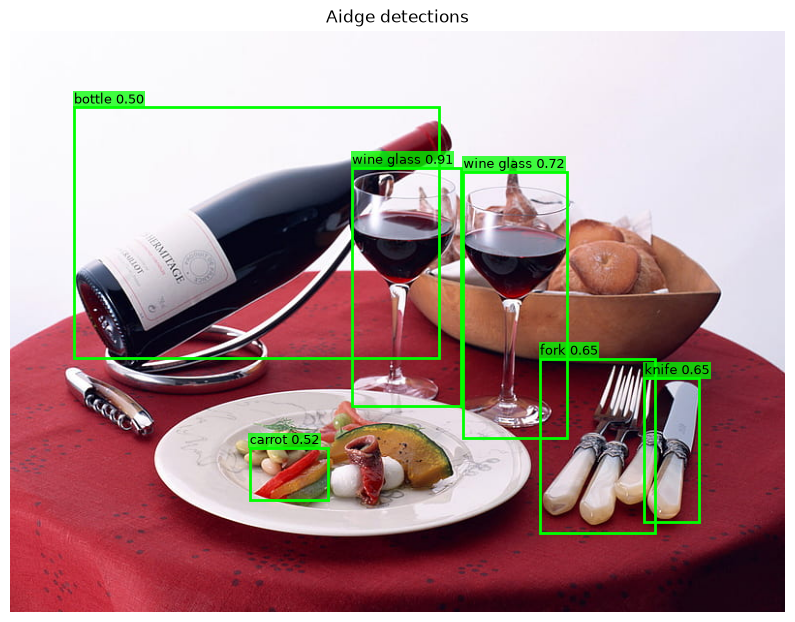

In [13]:
if aidge_outputs is None:
    print("Skipping Aidge detection plot because Aidge inference failed above.")
else:
    ort_max_score = float(sigmoid(ort_outputs["labels"]).max())
    aidge_max_score = float(sigmoid(aidge_outputs["labels"]).max())
    print(f"ONNX Runtime max score: {ort_max_score:.6f}")
    print(f"Aidge max score:        {aidge_max_score:.6f}")

    aidge_detections = top_detections(aidge_outputs, original_size, k=20, score_threshold=0.5)
    print(f"kept {len(aidge_detections)} Aidge detections")
    for score, label, box in aidge_detections[:10]:
        print(f"{COCO_NAMES.get(label, f'class_{label}'):<15} score={score:.4f} box={np.round(box, 1)}")
    draw_detections(image, aidge_detections, title="Aidge detections")


In [14]:
from collections import defaultdict

profile = []
by_type = defaultdict(float)

for item in aidge_scheduler.get_forward_scheduling():
    duration = item.duration_ns / 1e9
    node = item.node

    profile.append((duration, node.name(), node.type()))
    by_type[node.type()] += duration

print("Slowest individual nodes:")
for duration, name, op_type in sorted(profile, reverse=True)[:30]:
    print(f"{duration:9.4f}s  {op_type:20} {name}")

print("\nTotal time by operator type:")
for op_type, duration in sorted(
    by_type.items(), key=lambda item: item[1], reverse=True
)[:30]:
    print(f"{duration:9.4f}s  {op_type}")

Slowest individual nodes:
   0.3900s  SDShiftmax           backbone_backbone_0_encoder_blocks_1_attn_softmax_Mul_8_SDShiftmax
   0.3745s  SDShiftmax           backbone_backbone_0_encoder_blocks_3_attn_softmax_Mul_8_SDShiftmax
   0.3727s  SDShiftmax           backbone_backbone_0_encoder_blocks_5_attn_softmax_Mul_8_SDShiftmax
   0.1816s  Div                  backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Div_5
   0.1789s  Cast                 backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Cast
   0.1763s  Cast                 backbone_backbone_0_encoder_blocks_3_attn_qact_qk_matmul_out_Cast
   0.1728s  Round                backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Round_2
   0.1707s  Div                  backbone_backbone_0_encoder_blocks_3_attn_qact_qk_matmul_out_Div_5
   0.1704s  Mul                  backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Mul_1
   0.1696s  Cast                 backbone_backbone_0_encoder_blocks_3_attn

In [15]:
# visualize(aidge_model)

In [16]:
for node in aidge_model.get_nodes():
    op = node.get_operator()
    print(f"{node.name()} ({node.type()})")

    for i in range(op.nb_inputs()):
        tensor = op.get_input(i)
        if tensor is not None:
            print(f"  input#{i}: {tensor.dtype}")

    for i in range(op.nb_outputs()):
        tensor = op.get_output(i)
        print(f"  output#{i}: {tensor.dtype}")

transformer_decoder_layers_1_Mul_1 (Mul)
  input#0: dtype.float32
  input#1: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_1_Round_4 (Round)
  input#0: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_0_norm2_Floor_38 (Floor)
  input#0: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_1_Add_1 (Add)
  input#0: dtype.float32
  input#1: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_1_cross_attn_sampling_offsets_Add_2 (Add)
  input#0: dtype.float32
  input#1: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_1_Round_2 (Round)
  input#0: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_0_qact_cross_attn_block_Mul_2 (Mul)
  input#0: dtype.float32
  input#1: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_1_norm1_Div_2 (Div)
  input#0: dtype.float32
  input#1: dtype.float32
  output#0: dtype.float32
transformer_decoder_layers_0_qact_ffn_1_Cast_8 (Cast)
  input#0:

## Intermediate Output Comparison

This exposes selected internal ONNX tensors in ONNX Runtime, then reads the matching Aidge node outputs after the same forward pass. Use it to locate the first layer where the two executions diverge.


In [17]:

def build_debug_onnx(model_path, debug_points):
    model = onnx.load(str(model_path))
    try:
        inferred = shape_inference.infer_shapes(model)
    except Exception:
        inferred = model

    value_info = {}
    for collection in (inferred.graph.input, inferred.graph.value_info, inferred.graph.output):
        for value in collection:
            value_info[value.name] = value

    existing_outputs = {output.name for output in model.graph.output}
    for _, tensor_name, _, _ in debug_points:
        if tensor_name in existing_outputs:
            continue
        if tensor_name in value_info:
            model.graph.output.append(value_info[tensor_name])
        else:
            model.graph.output.append(helper.make_tensor_value_info(tensor_name, TensorProto.FLOAT, None))
        existing_outputs.add(tensor_name)

    debug_path = Path("/tmp/lwdetr_intermediate_debug.onnx")
    onnx.save(model, str(debug_path))
    return debug_path


def summarize_array(array):
    array = np.asarray(array)
    finite = np.isfinite(array) if np.issubdtype(array.dtype, np.floating) else np.ones(array.shape, dtype=bool)
    if array.size == 0 or not finite.any():
        return f"shape={array.shape} dtype={array.dtype} no finite values"
    values = array[finite]
    return (
        f"shape={array.shape} dtype={array.dtype} "
        f"min={values.min():.6g} max={values.max():.6g} mean={values.mean():.6g}"
    )


def run_onnxruntime_debug(batch, debug_points):
    debug_path = build_debug_onnx(MODEL_PATH, debug_points)
    session = ort.InferenceSession(str(debug_path), providers=["CPUExecutionProvider"])
    input_name = session.get_inputs()[0].name
    output_names = [output.name for output in session.get_outputs()]
    values = session.run(None, {input_name: batch})
    return dict(zip(output_names, values))


def run_aidge_debug(batch):
    aidge_input = aidge_core.Tensor(batch)
    aidge_input.to_dtype(aidge_core.dtype.float32)
    aidge_scheduler.forward(True, [aidge_input])


def get_aidge_node_output(node_name, output_index=0):
    node = aidge_model.get_node(node_name)
    if node is None:
        raise KeyError(f"Aidge node not found: {node_name}")
    return np.array(node.get_operator().get_output(output_index))


def compare_intermediate_outputs(batch=input_tensor, debug_points=None, atol=1e-4):
    ort_debug = run_onnxruntime_debug(batch, debug_points)
    run_aidge_debug(batch)

    rows = []
    first_bad = None
    for label, tensor_name, node_name, output_index in debug_points:
        if tensor_name not in ort_debug:
            rows.append((label, "missing_ort", tensor_name, node_name, None, None, None))
            continue
        ort_value = np.asarray(ort_debug[tensor_name])
        try:
            aidge_value = get_aidge_node_output(node_name, output_index)
        except Exception as exc:
            rows.append((label, "missing_aidge", str(exc), node_name, None, None, None))
            continue

        if ort_value.shape != aidge_value.shape:
            rows.append((label, "shape_mismatch", ort_value.shape, aidge_value.shape, None, None, None))
            if first_bad is None:
                first_bad = label
            continue

        diff = np.abs(ort_value.astype(np.float64) - aidge_value.astype(np.float64))
        max_abs = float(np.nanmax(diff))
        mean_abs = float(np.nanmean(diff))
        status = "ok" if max_abs <= atol else "diff"
        if status == "diff" and first_bad is None:
            first_bad = label
        rows.append((label, status, ort_value, aidge_value, max_abs, mean_abs, tensor_name))

    for label, status, left, right, max_abs, mean_abs, tensor_name in rows:
        print(f"\n{label}: {status}")
        if status in {"ok", "diff"}:
            print("  onnxruntime:", summarize_array(left))
            print("  aidge:      ", summarize_array(right))
            print(f"  max_abs={max_abs:.8g} mean_abs={mean_abs:.8g}")
            print("  tensor:", tensor_name)
        elif status == "shape_mismatch":
            print("  onnxruntime shape:", left)
            print("  aidge shape:      ", right)
        else:
            print(" ", left)
    print("\nfirst mismatch:", first_bad if first_bad is not None else "none within tolerance")
    return rows



In [18]:
DEBUG_POINTS = [
    # Backbone / ViT checkpoints
    (
        "patch_embed_conv",
        "/backbone/backbone.0/encoder/patch_embed/proj/Conv_output_0",
        "backbone_backbone_0_encoder_patch_embed_proj_Conv",
        0,
    ),
    (
        "vit_block0_out",
        "/backbone/backbone.0/encoder/blocks.0/Add_1_output_0",
        "backbone_backbone_0_encoder_blocks_0_Add_1",
        0,
    ),
    (
        "vit_block1_out",
        "/backbone/backbone.0/encoder/blocks.1/Add_1_output_0",
        "backbone_backbone_0_encoder_blocks_1_Add_1",
        0,
    ),
    (
        "vit_block2_out",
        "/backbone/backbone.0/encoder/blocks.2/Add_1_output_0",
        "backbone_backbone_0_encoder_blocks_2_Add_1",
        0,
    ),
    (
        "projector_stage0_norm",
        "/backbone/backbone.0/projector/stages.0.1/Add_1_output_0",
        "backbone_backbone_0_projector_stages_0_1_Add_1",
        0,
    ),

    # Transformer encoder / proposal selection
    (
        "topk_values",
        "/transformer/TopK_output_0",
        "transformer_TopK_output_0",
        0,
    ),
    (
        "topk_indices",
        "/transformer/TopK_output_1",
        "transformer_TopK_output_0",
        1,
    ),
    (
        "decoder_refpoints",
        "/transformer/decoder/Slice_output_0",
        "transformer_decoder_Slice",
        0,
    ),

    # First decoder layer / cross-attention checkpoints
    (
        "cross_attn_value_proj",
        "/transformer/decoder/layers.0/cross_attn/value_proj/Add_2_output_0",
        "transformer_decoder_layers_0_cross_attn_value_proj_Add_2",
        0,
    ),
    (
        "cross_attn_sampling_locations",
        "/transformer/decoder/layers.0/cross_attn/Add_output_0",
        "transformer_decoder_layers_0_cross_attn_Add_output_0",
        0,
    ),
    (
        "cross_attn_sampling_locations_q",
        "/transformer/decoder/layers.0/cross_attn/Add_3_output_0",
        "transformer_decoder_layers_0_cross_attn_Add_3",
        0,
    ),
    (
        "cross_attn_output_proj",
        "/transformer/decoder/layers.0/cross_attn/output_proj/Add_2_output_0",
        "transformer_decoder_layers_0_cross_attn_output_proj_Add_2",
        0,
    ),
    (
        "decoder_layer0_out",
        "/transformer/decoder/layers.0/Add_3_output_0",
        "transformer_decoder_layers_0_Add_3",
        0,
    ),
    (
        "decoder_layer1_out",
        "/transformer/decoder/layers.1/Add_3_output_0",
        "transformer_decoder_layers_1_Add_3",
        0,
    ),
    (
        "decoder_layer2_out",
        "/transformer/decoder/layers.2/Add_3_output_0",
        "transformer_decoder_layers_2_Add_3",
        0,
    ),

    # Final exported outputs
    (
        "final_dets",
        "dets",
        "Concat",
        0,
    ),
    (
        "final_labels",
        "labels",
        "class_embed_Mul_5",
        0,
    ),
]

intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)


patch_embed_conv: ok
  onnxruntime: shape=(1, 192, 40, 40) dtype=float32 min=-3.51506e+06 max=1.79877e+06 mean=5938.55
  aidge:       shape=(1, 192, 40, 40) dtype=float32 min=-3.51506e+06 max=1.79877e+06 mean=5938.55
  max_abs=0 mean_abs=0
  tensor: /backbone/backbone.0/encoder/patch_embed/proj/Conv_output_0

vit_block0_out: ok
  onnxruntime: shape=(16, 100, 192) dtype=float32 min=-40701 max=28898 mean=230.82
  aidge:       shape=(16, 100, 192) dtype=float32 min=-40701 max=28898 mean=230.82
  max_abs=0 mean_abs=0
  tensor: /backbone/backbone.0/encoder/blocks.0/Add_1_output_0

vit_block1_out: diff
  onnxruntime: shape=(16, 100, 192) dtype=float32 min=-42046 max=12909 mean=97.7977
  aidge:       shape=(16, 100, 192) dtype=float32 min=-42046 max=12826 mean=97.7953
  max_abs=321 mean_abs=0.24633789
  tensor: /backbone/backbone.0/encoder/blocks.1/Add_1_output_0

vit_block2_out: diff
  onnxruntime: shape=(16, 100, 192) dtype=float32 min=-35390 max=8285 mean=51.6259
  aidge:       shape=(16,

In [ ]:
DEBUG_POINTS = [
    # Boundary: block 0 output is still exact
    ("vit_block0_out",
     "/backbone/backbone.0/encoder/blocks.0/Add_1_output_0",
     "backbone_backbone_0_encoder_blocks_0_Add_1", 0),

    # Block 1 norm / quant input to attention
    ("b1_norm1_out",
     "/backbone/backbone.0/encoder/blocks.1/norm1/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm1_Mul_2", 0),

    ("b1_pre_attn_scaler",
     "/backbone/backbone.0/encoder/blocks.1/pre_attn_scaler/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_pre_attn_scaler_Mul_2", 0),

    # QKV projection
    ("b1_qkv_matmul",
     "/backbone/backbone.0/encoder/blocks.1/attn/qkv/MatMul_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qkv_MatMul", 0),

    ("b1_qkv_out",
     "/backbone/backbone.0/encoder/blocks.1/attn/qkv/Mul_3_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qkv_Mul_3", 0),

    ("b1_attn_add",
     "/backbone/backbone.0/encoder/blocks.1/attn/Add_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_Add", 0),

    ("b1_qact_qkv",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_qkv/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_qkv_Mul_2", 0),

    # Q / K / V split
    ("b1_q",
     "/backbone/backbone.0/encoder/blocks.1/attn/Gather_3_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_Gather_3", 0),

    ("b1_k",
     "/backbone/backbone.0/encoder/blocks.1/attn/Gather_4_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_Gather_4", 0),

    ("b1_v",
     "/backbone/backbone.0/encoder/blocks.1/attn/Gather_5_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_Gather_5", 0),

    ("b1_qact_q",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_q/Add_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_q_Add", 0),

    ("b1_qact_k",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_k/Add_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_k_Add", 0),

    ("b1_qact_v",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_v/Add_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_v_Add", 0),

    # MLP path
    ("b1_norm2_out",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Mul_2", 0),

    ("b1_mlp_fc1",
     "/backbone/backbone.0/encoder/blocks.1/mlp/fc1/Add_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_fc1_Add_2", 0),

    ("b1_pre_gelu_qact",
     "/backbone/backbone.0/encoder/blocks.1/mlp/qact_pre_gelu/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_qact_pre_gelu_Mul_2", 0),

    ("b1_gelu_out",
     "/backbone/backbone.0/encoder/blocks.1/mlp/act_sign_no_lambda/Mul_11_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_act_sign_no_lambda_Mul_11", 0),

    ("b1_post_gelu_qact",
     "/backbone/backbone.0/encoder/blocks.1/mlp/qact_post_gelu/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_qact_post_gelu_Mul_2", 0),

    ("b1_mlp_fc2",
     "/backbone/backbone.0/encoder/blocks.1/mlp/fc2/Add_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_fc2_Add_2", 0),

    # Boundary: first known mismatch
    ("vit_block1_out",
     "/backbone/backbone.0/encoder/blocks.1/Add_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_Add_1", 0),
]

intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)

In [ ]:
DEBUG_POINTS = [
    ("b1_qact_q",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_q/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_q_Mul_2", 0),

    ("b1_qact_k",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_k/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_k_Mul_2", 0),

    ("b1_qact_v",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_v/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_v_Mul_2", 0),

    ("b1_qk_matmul",
     "/backbone/backbone.0/encoder/blocks.1/attn/matmul/Mul_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_matmul_Mul_1", 0),

    ("b1_qk_qact",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_qk_matmul_out/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Mul_2", 0),

    ("b1_softmax_out",
     "/backbone/backbone.0/encoder/blocks.1/attn/softmax/Mul_7_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_softmax_Mul_7", 0),

    ("b1_av_matmul",
     "/backbone/backbone.0/encoder/blocks.1/attn/matmul_1/Mul_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_matmul_1_Mul_1", 0),

    ("b1_av_qact",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_av_matmul_out/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_av_matmul_out_Mul_2", 0),

    ("b1_pre_proj",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_pre_proj/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_pre_proj_Mul_2", 0),

    ("b1_proj",
     "/backbone/backbone.0/encoder/blocks.1/attn/proj/Add_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_proj_Add_2", 0),

    ("b1_proj_qact",
     "/backbone/backbone.0/encoder/blocks.1/attn/qact_proj_drop/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_attn_qact_proj_drop_Mul_2", 0),

    ("b1_residual_after_attn",
     "/backbone/backbone.0/encoder/blocks.1/Add_output_0",
     "backbone_backbone_0_encoder_blocks_1_Add", 0),

    ("b1_qact_drop_1",
     "/backbone/backbone.0/encoder/blocks.1/qact_drop_1/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_qact_drop_1_Mul_2", 0),

    ("b1_norm2_out",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Mul_2", 0),

    ("b1_pre_mlp_scaler",
     "/backbone/backbone.0/encoder/blocks.1/pre_mlp_scaler/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_pre_mlp_scaler_Mul_2", 0),

    ("b1_mlp_fc1",
     "/backbone/backbone.0/encoder/blocks.1/mlp/fc1/Add_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_mlp_fc1_Add_2", 0),
]

intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)

In [ ]:
DEBUG_POINTS = [
    ("b1_norm2_input",
     "/backbone/backbone.0/encoder/blocks.1/qact_drop_1/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_qact_drop_1_Mul_2", 0),

    ("b1_norm2_div0",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Div_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Div", 0),

    ("b1_norm2_round0",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Round_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Round", 0),

    ("b1_norm2_reduce_mean_sum",
     "/backbone/backbone.0/encoder/blocks.1/norm2/ReduceSum_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_ReduceSum", 0),

    ("b1_norm2_mean_div",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Div_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Div_1", 0),

    ("b1_norm2_mean_round",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Round_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Round_1", 0),

    ("b1_norm2_centered",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Sub_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Sub", 0),

    # ("b1_norm2_square",
    #  "/backbone/backbone.0/encoder/blocks.1/norm2/Pow_output_0",
    #  "backbone_backbone_0_encoder_blocks_1_norm2_Pow", 0),

    ("b1_norm2_var_sum",
     "/backbone/backbone.0/encoder/blocks.1/norm2/ReduceSum_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_ReduceSum_1", 0),

    ("b1_norm2_var_div",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Div_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Div_2", 0),

    ("b1_norm2_reciprocal",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Reciprocal_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Reciprocal", 0),

    ("b1_norm2_before_final_scale",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Mul_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Mul_1", 0),

    ("b1_norm2_final",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Mul_2_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Mul_2", 0),
]
intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)

In [ ]:
DEBUG_POINTS = [
    ("b1_norm2_centered",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Sub_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Sub", 0),

    # ("b1_norm2_pow",
    #  "/backbone/backbone.0/encoder/blocks.1/norm2/Pow_output_0",
    #  "backbone_backbone_0_encoder_blocks_1_norm2_Pow", 0),

    ("b1_norm2_var_sum",
     "/backbone/backbone.0/encoder/blocks.1/norm2/ReduceSum_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_ReduceSum_1", 0),
]
intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)

In [ ]:
DEBUG_POINTS = [
    ("b1_norm2_centered",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Sub_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Sub", 0),

    ("b1_norm2_square_mul",
     "/backbone/backbone.0/encoder/blocks.1/norm2/Mul_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_Mul", 0),

    ("b1_norm2_var_sum",
     "/backbone/backbone.0/encoder/blocks.1/norm2/ReduceSum_1_output_0",
     "backbone_backbone_0_encoder_blocks_1_norm2_ReduceSum_1", 0),
]
intermediate_rows = compare_intermediate_outputs(debug_points=DEBUG_POINTS)

In [ ]:
for name in ort_outputs:
    a = aidge_outputs[name]
    b = ort_outputs[name]

    diff = np.abs(a - b)
    print(
        name,
        "shape", a.shape,
        "max_abs", diff.max(),
        "mean_abs", diff.mean(),
        "max_rel", (diff / (np.abs(b) + 1e-8)).max(),
        "aidge range", (a.min(), a.max()),
        "ort range", (b.min(), b.max()),
    )

## Compare ONNX Runtime and Aidge Outputs

In [ ]:
def compare_outputs(reference, candidate):
    rows = []
    for name in reference:
        ref = np.asarray(reference[name])
        got = np.asarray(candidate[name])
        if ref.shape != got.shape:
            rows.append((name, ref.shape, got.shape, None, None, None))
            continue
        diff = np.abs(ref - got)
        rows.append((name, ref.shape, got.shape, diff.max(), diff.mean(), np.median(diff)))
    return rows


if aidge_outputs is None:
    print("Skipping output comparison because Aidge inference failed above.")
else:
    for name, ref_shape, got_shape, max_abs, mean_abs, median_abs in compare_outputs(ort_outputs, aidge_outputs):
        print(f"{name}")
        print(f"  onnxruntime shape: {ref_shape}")
        print(f"  aidge shape:       {got_shape}")
        if max_abs is None:
            print("  shape mismatch; cannot compare values")
        else:
            print(f"  max abs diff:     {max_abs:.8g}")
            print(f"  mean abs diff:    {mean_abs:.8g}")
            print(f"  median abs diff:  {median_abs:.8g}")


## Compare Several Images

In [ ]:
if aidge_outputs is None:
    print("Skipping multi-image Aidge comparison because Aidge inference failed above.")
else:
    for path in image_paths:
        img = load_image(path)
        batch, _ = preprocess(img)
        ort_out = run_onnxruntime(batch)
        try:
            aidge_out, _ = run_aidge(batch)
        except Exception as exc:
            print()
            print(path.name, "Aidge failed:", exc)
            continue

        ort_dets = top_detections(ort_out, img.size, k=20, score_threshold=0.5)
        aidge_dets = top_detections(aidge_out, img.size, k=20, score_threshold=0.5)
        print()
        print(path.name)
        print(f"  ONNX Runtime detections: {len(ort_dets)}")
        print(f"  Aidge detections:        {len(aidge_dets)}")
        print(f"  ONNX Runtime max score:  {float(sigmoid(ort_out['labels']).max()):.6f}")
        print(f"  Aidge max score:         {float(sigmoid(aidge_out['labels']).max()):.6f}")
        for name, _, _, max_abs, mean_abs, _ in compare_outputs(ort_out, aidge_out):
            if max_abs is None:
                print(f"  {name}: shape mismatch")
            else:
                print(f"  {name}: max_abs={max_abs:.8g}, mean_abs={mean_abs:.8g}")
        draw_detection_comparison(img, ort_dets, aidge_dets, title=path.name)
